# 02 Baselines: majority class and TF-IDF bag-of-words models

**Why these baselines?**
* The **majority-class** model is the floor: it predicts the training class shares for every article.
* **TF-IDF + Multinomial Naive Bayes** is the classic text-classification baseline and one of the classical baselines
  in the MasakhaNEWS paper (Adelani et al., 2023), so we can compare with published numbers.
* **TF-IDF + Logistic Regression / linear SVM** are strong linear models that are hard to beat on small datasets
  (Joulin et al., 2017), so any neural model has to justify its extra cost against them.

**Protocol.** Every setting is scored on the validation set *and* with 5-fold cross-validation on the training set
repeated 3 times (15 folds). We choose settings by the **cross-validation mean macro-F1**, because the validation set
has only 87 articles. The test set is used once, at the end, for the chosen models.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Change this to your own GitHub repository before running in Colab
REPO_URL = "https://github.com/YOUR-GITHUB-USERNAME/lingala-news-classification.git"

if IN_COLAB and not Path("lingala-news-classification").exists():
    !git clone -q {REPO_URL}
if IN_COLAB:
    %cd lingala-news-classification
    %pip install -q -r requirements.txt

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /home/claude/lingala-news-classification


In [2]:
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from src import classical_models, config, data_loading, evaluation, plots
from src.cross_validation import cross_validate
from src.experiment_log import log_experiment

MODEL_FAMILY = "bag_of_words"

train, validation, test = data_loading.load_all_splits()
train_ids = data_loading.labels_to_ids(train["category"])
validation_ids = data_loading.labels_to_ids(validation["category"])
test_ids = data_loading.labels_to_ids(test["category"])

In [3]:
results = []

def run(name, settings, notes, text_column=config.TEXT_COLUMN):
    """Fit on train, score on validation, cross-validate on train, log everything."""
    pipeline = classical_models.build_pipeline(settings).fit(train[text_column], train_ids)
    validation_scores = evaluation.compute_scores(validation_ids, pipeline.predict_proba(validation[text_column]))
    cv_scores = cross_validate(lambda: classical_models.build_pipeline(settings), train, text_column)
    all_settings = {**settings, "text_column": text_column}
    log_experiment(MODEL_FAMILY, name, "validation", all_settings, validation_scores, notes)
    log_experiment(MODEL_FAMILY, name, "cv_train", all_settings,
                   {k: v for k, v in cv_scores.items()}, notes)
    results.append({
        "experiment": name,
        "val_macro_f1": validation_scores["macro_f1"],
        "val_weighted_f1": validation_scores["weighted_f1"],
        "cv_macro_f1": cv_scores["macro_f1"],
        "cv_macro_f1_std": cv_scores["macro_f1_std"],
        "settings": all_settings,
    })
    print(f"{name:32s} val macro-F1 {validation_scores['macro_f1']:.3f} | "
          f"CV macro-F1 {cv_scores['macro_f1']:.3f} ± {cv_scores['macro_f1_std']:.3f}")
    return pipeline

## Experiment group A: which classifier?
All use word-unigram TF-IDF features on headline + text.

In [4]:
run("A1_majority", {"classifier": "majority"}, "Floor: predicts class shares")
run("A2_nb_alpha1", {"classifier": "naive_bayes", "features": "word", "alpha": 1.0}, "Default NB smoothing")
run("A3_nb_alpha0.1", {"classifier": "naive_bayes", "features": "word", "alpha": 0.1}, "Less smoothing")
run("A4_complement_nb", {"classifier": "complement_nb", "features": "word", "alpha": 0.3}, "Complement NB for unbalanced classes")
run("A5_logreg", {"classifier": "logistic_regression", "features": "word", "C": 10}, "Logistic regression, no class weights")
run("A6_logreg_balanced", {"classifier": "logistic_regression", "features": "word", "C": 10, "class_weight": True}, "Balanced class weights")
run("A7_svm_balanced", {"classifier": "linear_svm", "features": "word", "C": 1, "class_weight": True}, "Linear SVM, calibrated");

Logged 'A1_majority' (validation) to bag_of_words.csv
Logged 'A1_majority' (cv_train) to bag_of_words.csv
A1_majority                      val macro-F1 0.182 | CV macro-F1 0.183 ± 0.001


Logged 'A2_nb_alpha1' (validation) to bag_of_words.csv
Logged 'A2_nb_alpha1' (cv_train) to bag_of_words.csv
A2_nb_alpha1                     val macro-F1 0.233 | CV macro-F1 0.216 ± 0.020


Logged 'A3_nb_alpha0.1' (validation) to bag_of_words.csv
Logged 'A3_nb_alpha0.1' (cv_train) to bag_of_words.csv
A3_nb_alpha0.1                   val macro-F1 0.753 | CV macro-F1 0.684 ± 0.029


Logged 'A4_complement_nb' (validation) to bag_of_words.csv
Logged 'A4_complement_nb' (cv_train) to bag_of_words.csv
A4_complement_nb                 val macro-F1 0.828 | CV macro-F1 0.746 ± 0.048


Logged 'A5_logreg' (validation) to bag_of_words.csv
Logged 'A5_logreg' (cv_train) to bag_of_words.csv
A5_logreg                        val macro-F1 0.787 | CV macro-F1 0.760 ± 0.035


Logged 'A6_logreg_balanced' (validation) to bag_of_words.csv
Logged 'A6_logreg_balanced' (cv_train) to bag_of_words.csv
A6_logreg_balanced               val macro-F1 0.902 | CV macro-F1 0.840 ± 0.049


Logged 'A7_svm_balanced' (validation) to bag_of_words.csv
Logged 'A7_svm_balanced' (cv_train) to bag_of_words.csv
A7_svm_balanced                  val macro-F1 0.902 | CV macro-F1 0.854 ± 0.045


**What happened with Naive Bayes at alpha = 1?** TF-IDF values are small (each row is normalised to length 1), so
the word "counts" NB sees are tiny compared with the add-one smoothing. Every word then looks almost equally likely in every
class, and the class prior (57% politics) decides. With alpha = 0.1 the evidence from the words is no longer drowned out.
This is a good reminder that default hyper-parameters are tuned for raw counts on large corpora.

**Class weights** make a mistake on a business article cost about six times as much as one on a politics article, which
forces the model to learn the small classes. This is the biggest single gain in this group.

## Experiment group B: which features?
Logistic regression with balanced class weights, because it is fast, gives probabilities, and its weights can be read.

In [5]:
LOGREG = {"classifier": "logistic_regression", "C": 10, "class_weight": True}
run("B1_word_1-2grams", {**LOGREG, "features": "word", "word_ngrams": (1, 2)}, "Adds word pairs")
run("B2_char_2-5", {**LOGREG, "features": "char", "char_ngrams": (2, 5)}, "Character n-grams inside words")
run("B3_char_3-6", {**LOGREG, "features": "char", "char_ngrams": (3, 6)}, "Longer character n-grams")
run("B4_word+char", {**LOGREG, "features": "word+char"}, "Word 1-2 grams + char 2-5 grams")
run("B5_svm_word+char", {"classifier": "linear_svm", "C": 1, "class_weight": True, "features": "word+char"}, "SVM on word+char");

Logged 'B1_word_1-2grams' (validation) to bag_of_words.csv
Logged 'B1_word_1-2grams' (cv_train) to bag_of_words.csv
B1_word_1-2grams                 val macro-F1 0.866 | CV macro-F1 0.789 ± 0.048


Logged 'B2_char_2-5' (validation) to bag_of_words.csv
Logged 'B2_char_2-5' (cv_train) to bag_of_words.csv
B2_char_2-5                      val macro-F1 0.868 | CV macro-F1 0.852 ± 0.024


Logged 'B3_char_3-6' (validation) to bag_of_words.csv
Logged 'B3_char_3-6' (cv_train) to bag_of_words.csv
B3_char_3-6                      val macro-F1 0.868 | CV macro-F1 0.848 ± 0.029


Logged 'B4_word+char' (validation) to bag_of_words.csv
Logged 'B4_word+char' (cv_train) to bag_of_words.csv
B4_word+char                     val macro-F1 0.881 | CV macro-F1 0.845 ± 0.032


Logged 'B5_svm_word+char' (validation) to bag_of_words.csv
Logged 'B5_svm_word+char' (cv_train) to bag_of_words.csv
B5_svm_word+char                 val macro-F1 0.881 | CV macro-F1 0.855 ± 0.022


## Experiment group C: input text and preprocessing
Using the best feature set so far, we change only the input.

In [6]:
table = pd.DataFrame(results)
best_feature_run = table[table["experiment"].str.startswith(("A", "B"))].sort_values("cv_macro_f1", ascending=False).iloc[0]
BEST = {k: v for k, v in best_feature_run["settings"].items() if k != "text_column"}
print("Best so far by CV:", best_feature_run["experiment"], BEST)

run("C1_headline_only", BEST, "Only the headline", text_column="headline")
run("C2_text_only", BEST, "Only the body text", text_column="text")
run("C3_strip_accents", {**BEST, "strip_accents": True}, "Remove accents: été -> ete, Léopards -> Leopards");

Best so far by CV: B5_svm_word+char {'classifier': 'linear_svm', 'C': 1, 'class_weight': True, 'features': 'word+char'}


Logged 'C1_headline_only' (validation) to bag_of_words.csv
Logged 'C1_headline_only' (cv_train) to bag_of_words.csv
C1_headline_only                 val macro-F1 0.762 | CV macro-F1 0.711 ± 0.039


Logged 'C2_text_only' (validation) to bag_of_words.csv
Logged 'C2_text_only' (cv_train) to bag_of_words.csv
C2_text_only                     val macro-F1 0.881 | CV macro-F1 0.851 ± 0.020


Logged 'C3_strip_accents' (validation) to bag_of_words.csv
Logged 'C3_strip_accents' (cv_train) to bag_of_words.csv
C3_strip_accents                 val macro-F1 0.881 | CV macro-F1 0.858 ± 0.022


## Experiment group D: regularisation strength

In [7]:
if BEST["classifier"] in {"logistic_regression", "linear_svm"}:
    for C in ([1, 100] if BEST["classifier"] == "logistic_regression" else [0.1, 10]):
        run(f"D_C={C}", {**BEST, "C": C}, "Smaller C = stronger regularisation")

Logged 'D_C=0.1' (validation) to bag_of_words.csv
Logged 'D_C=0.1' (cv_train) to bag_of_words.csv
D_C=0.1                          val macro-F1 0.902 | CV macro-F1 0.843 ± 0.029


Logged 'D_C=10' (validation) to bag_of_words.csv
Logged 'D_C=10' (cv_train) to bag_of_words.csv
D_C=10                           val macro-F1 0.881 | CV macro-F1 0.861 ± 0.028


## Summary of all experiments

In [8]:
table = pd.DataFrame(results).drop(columns="settings")
table.sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)

,experiment,val_macro_f1,val_weighted_f1,cv_macro_f1,cv_macro_f1_std
0,D_C=10,0.8811,0.9068,0.8608,0.0276
1,C3_strip_accents,0.8811,0.9068,0.8575,0.0224
2,B5_svm_word+char,0.8811,0.9068,0.8554,0.0219
3,A7_svm_balanced,0.9018,0.9189,0.8537,0.0455
4,B2_char_2-5,0.8675,0.8967,0.8522,0.0235
5,C2_text_only,0.8811,0.9068,0.8509,0.0200
6,B3_char_3-6,0.8675,0.8967,0.8475,0.0285
7,B4_word+char,0.8811,0.9068,0.8453,0.0319
8,D_C=0.1,0.9018,0.9189,0.8429,0.0287
9,A6_logreg_balanced,0.9018,0.9189,0.8398,0.0487


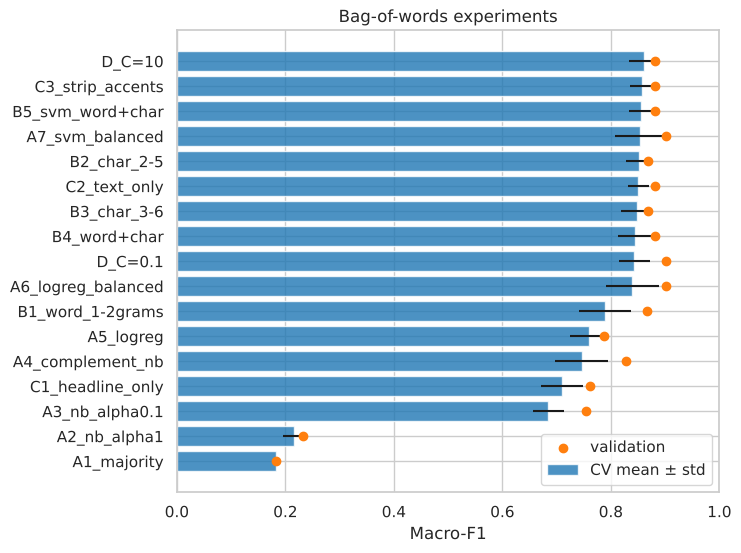

In [9]:
figure, axis = plt.subplots(figsize=(7, 6))
ordered = table.sort_values("cv_macro_f1")
axis.barh(ordered["experiment"], ordered["cv_macro_f1"], xerr=ordered["cv_macro_f1_std"], color="tab:blue", alpha=0.8, label="CV mean ± std")
axis.scatter(ordered["val_macro_f1"], ordered["experiment"], color="tab:orange", zorder=3, label="validation")
axis.set_xlabel("Macro-F1")
axis.set_xlim(0, 1)
axis.legend(loc="lower right")
axis.set_title("Bag-of-words experiments")
plots.save(figure, "bag_of_words", "experiments.png");

## Final models on the test set (used once)
We evaluate three models: the majority floor, the best Naive Bayes (the classical baseline the paper reports), and the best
configuration overall by cross-validation. Each is refit on the training set only (validation is not added) so that every model
family in this project sees exactly the same training data.

In [10]:
full_table = pd.DataFrame(results)
best_overall = full_table.sort_values("cv_macro_f1", ascending=False).iloc[0]
best_nb = full_table[full_table["settings"].apply(lambda s: s.get("classifier") in {"naive_bayes", "complement_nb"})].sort_values("cv_macro_f1", ascending=False).iloc[0]
finalists = {
    "majority": full_table.set_index("experiment").loc["A1_majority", "settings"],
    "tfidf_naive_bayes": best_nb["settings"],
    "tfidf_best": best_overall["settings"],
}
print("Best overall:", best_overall["experiment"], best_overall["settings"])
print("Best NB:", best_nb["experiment"])

final_pipelines = {}
for model_name, settings in finalists.items():
    column = settings.get("text_column", config.TEXT_COLUMN)
    fit_settings = {k: v for k, v in settings.items() if k != "text_column"}
    pipeline = classical_models.build_pipeline(fit_settings).fit(train[column], train_ids)
    probabilities = pipeline.predict_proba(test[column])
    scores = evaluation.compute_scores(test_ids, probabilities)
    low, high = evaluation.bootstrap_confidence_interval(test_ids, probabilities.argmax(1))
    scores["macro_f1_ci_low"], scores["macro_f1_ci_high"] = low, high
    log_experiment(MODEL_FAMILY, f"FINAL_{model_name}", "test", settings, scores, "Final test evaluation")
    evaluation.save_test_predictions(probabilities, model_name)
    final_pipelines[model_name] = pipeline
    print(f"\n=== {model_name}: test macro-F1 {scores['macro_f1']:.3f} (95% CI {low:.3f}-{high:.3f}), weighted-F1 {scores['weighted_f1']:.3f}")
    evaluation.print_classification_report(test_ids, probabilities)

Best overall: D_C=10 {'classifier': 'linear_svm', 'C': 10, 'class_weight': True, 'features': 'word+char', 'text_column': 'content'}
Best NB: A4_complement_nb


Logged 'FINAL_majority' (test) to bag_of_words.csv
Saved test probabilities to /home/claude/lingala-news-classification/results/predictions/majority.csv

=== majority: test macro-F1 0.182 (95% CI 0.165-0.196), weighted-F1 0.416
              precision    recall  f1-score   support

    politics      0.571     1.000     0.727       100
      health      0.000     0.000     0.000        39
      sports      0.000     0.000     0.000        19
    business      0.000     0.000     0.000        17

    accuracy                          0.571       175
   macro avg      0.143     0.250     0.182       175
weighted avg      0.327     0.571     0.416       175



Logged 'FINAL_tfidf_naive_bayes' (test) to bag_of_words.csv
Saved test probabilities to /home/claude/lingala-news-classification/results/predictions/tfidf_naive_bayes.csv

=== tfidf_naive_bayes: test macro-F1 0.673 (95% CI 0.609-0.738), weighted-F1 0.773
              precision    recall  f1-score   support

    politics      0.756     0.990     0.857       100
      health      0.960     0.615     0.750        39
      sports      1.000     0.947     0.973        19
    business      1.000     0.059     0.111        17

    accuracy                          0.811       175
   macro avg      0.929     0.653     0.673       175
weighted avg      0.852     0.811     0.773       175



Logged 'FINAL_tfidf_best' (test) to bag_of_words.csv
Saved test probabilities to /home/claude/lingala-news-classification/results/predictions/tfidf_best.csv

=== tfidf_best: test macro-F1 0.822 (95% CI 0.747-0.884), weighted-F1 0.852
              precision    recall  f1-score   support

    politics      0.826     0.950     0.884       100
      health      0.933     0.718     0.812        39
      sports      1.000     0.947     0.973        19
    business      0.750     0.529     0.621        17

    accuracy                          0.857       175
   macro avg      0.877     0.786     0.822       175
weighted avg      0.861     0.857     0.852       175



Saved 25 misclassified test articles to /home/claude/lingala-news-classification/results/misclassified/tfidf_best.csv


,headline,true_label,predicted_label,confidence
26,UE elaki Tshisekedi kobakisa 50 millions $ mpo...,health,politics,0.9229
10,Basali ya société canadienne Banro bakangami n...,business,politics,0.9023
48,Assemblée nationale endimi kobakisi mikolo na ...,health,politics,0.8763
41,Parlement endimi kobakisa mikolo na état d'urg...,health,politics,0.8302
3,Sassou asengi lisungi mpo na Fonds bleu ya bas...,business,politics,0.8213
14,Ouganda na RDC batie manzaka na boyokani mpo n...,business,politics,0.8144
111,"Pompeo akebisi mpo na ""bilaka ya bampa"" ya Chi...",politics,business,0.7877
25,"Kamerhe atiami na ""respiration artificielle"" (...",health,politics,0.7740
60,111 Congolais bakangamaki na France mpe na Bel...,politics,health,0.7534
53,Ruberwa atindami na mbalakaka na Afrique du Su...,health,politics,0.7382


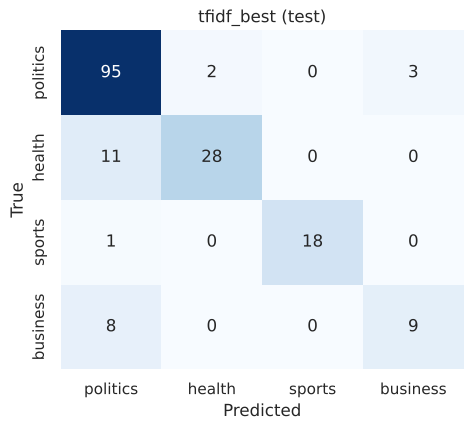

In [11]:
best_probabilities = final_pipelines["tfidf_best"].predict_proba(test[config.TEXT_COLUMN])
plots.plot_confusion_matrix(test_ids, best_probabilities, "tfidf_best", "test")
evaluation.save_misclassified_examples(test, test_ids, best_probabilities, "tfidf_best").head(10)[["headline", "true_label", "predicted_label", "confidence"]]

## Save the model for the web app
The pipeline contains both the TF-IDF vocabulary and the classifier, so the app can call `predict_proba` on raw text.

In [12]:
config.MODELS_DIRECTORY.mkdir(exist_ok=True)
joblib.dump(final_pipelines["tfidf_best"], config.MODELS_DIRECTORY / "tfidf_classifier.joblib")
metadata = {"labels": config.LABELS, "settings": best_overall["settings"], "experiment": best_overall["experiment"]}
(config.MODELS_DIRECTORY / "tfidf_classifier.json").write_text(json.dumps(metadata, indent=2, default=str))
print("Saved", config.MODELS_DIRECTORY / "tfidf_classifier.joblib")

Saved /home/claude/lingala-news-classification/models/tfidf_classifier.joblib


## What did the best linear model learn?

In [13]:
pipeline = final_pipelines["tfidf_best"]
if hasattr(pipeline.named_steps["classifier"], "coef_"):
    top = classical_models.top_features_per_class(pipeline, 20)
    display(pd.DataFrame({label: words for label, words in top.items()}))
else:
    # Calibrated SVM: average the coefficients of the internal SVMs
    import numpy as np
    calibrated = pipeline.named_steps["classifier"].calibrated_classifiers_
    coefficients = np.mean([c.estimator.coef_ for c in calibrated], axis=0)
    names = pipeline.named_steps["tfidf"].get_feature_names_out()
    display(pd.DataFrame({label: [names[i] for i in coefficients[k].argsort()[::-1][:20]] for k, label in enumerate(config.LABELS)}))

,politics,health,sports,business
0,word__maponami,word__covid,word__léopards,word__bad
1,word__mokonzi,word__covid 19,word__club,word__banque
2,word__mampinga,word__19,word__ba léopards,word__misolo
3,word__na bokonzi,word__bokono,word__caf,word__mines
4,word__basoda,word__ebola,word__ndembo,word__pétrole
5,word__bokonzi,word__na covid,word__basani,word__fmi
6,word__mokonzi ya,char__ono,word__finale,word__ya bad
7,char__pona,char__ono,word__mongete,word__mombongo
8,char__nami,char__ cov,char__pards,word__makele
9,word__cour,char__ covi,char__opard,char__banqu
